In [1]:
#Dídac Tresserres Saló i JAvier Martinez Hernandez
#1703771 i 1708408

In [2]:
# 1.Importació de llibreries bàsiques
#--------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy.stats import poisson

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.calibration import CalibratedClassifierCV

from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score, 
    classification_report, 
    mean_squared_error, 
    mean_absolute_error, 
    r2_score
)

from sklearn.inspection import permutation_importance

from sklearn.exceptions import ConvergenceWarning


In [3]:
#2.Carrega i neteja de les dades
#--------------------------------

df = pd.read_csv(r"C:\Users\niltr\OneDrive\Escritorio\UNI\3r de carrera\APC\Kaggle\archive\epl_final.csv")
#df = pd.read_csv(r"C:\Users\javie\OneDrive\Documentos\UNI\AC\Kaggle\archive\epl_final.csv")

df.head()

,Season,MatchDate,HomeTeam,AwayTeam,FullTimeHomeGoals,FullTimeAwayGoals,FullTimeResult,HalfTimeHomeGoals,HalfTimeAwayGoals,HalfTimeResult,...,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards
0,2000/01,2000-08-19,Charlton,Man City,4,0,H,2,0,H,...,14,4,6,6,13,12,1,2,0,0
1,2000/01,2000-08-19,Chelsea,West Ham,4,2,H,1,0,H,...,10,5,7,7,19,14,1,2,0,0
2,2000/01,2000-08-19,Coventry,Middlesbrough,1,3,A,1,1,D,...,3,9,8,4,15,21,5,3,1,0
3,2000/01,2000-08-19,Derby,Southampton,2,2,D,1,2,A,...,4,6,5,8,11,13,1,1,0,0
4,2000/01,2000-08-19,Leeds,Everton,2,0,H,2,0,H,...,8,6,6,4,21,20,1,3,0,0


In [4]:
print(df.shape)
print(df.dtypes)

df.describe(include='all')


(9380, 22)
Season               object
MatchDate            object
HomeTeam             object
AwayTeam             object
FullTimeHomeGoals     int64
FullTimeAwayGoals     int64
FullTimeResult       object
HalfTimeHomeGoals     int64
HalfTimeAwayGoals     int64
HalfTimeResult       object
HomeShots             int64
AwayShots             int64
HomeShotsOnTarget     int64
AwayShotsOnTarget     int64
HomeCorners           int64
AwayCorners           int64
HomeFouls             int64
AwayFouls             int64
HomeYellowCards       int64
AwayYellowCards       int64
HomeRedCards          int64
AwayRedCards          int64
dtype: object


,Season,MatchDate,HomeTeam,AwayTeam,FullTimeHomeGoals,FullTimeAwayGoals,FullTimeResult,HalfTimeHomeGoals,HalfTimeAwayGoals,HalfTimeResult,...,HomeShotsOnTarget,AwayShotsOnTarget,HomeCorners,AwayCorners,HomeFouls,AwayFouls,HomeYellowCards,AwayYellowCards,HomeRedCards,AwayRedCards
count,9380,9380,9380,9380,9380.000000,9380.000000,9380,9380.000000,9380.000000,9380,...,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000,9380.000000
unique,25,2599,46,46,NaN,NaN,3,NaN,NaN,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,2000/01,2011-05-22,Everton,Liverpool,NaN,NaN,H,NaN,NaN,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,380,10,471,471,NaN,NaN,4299,NaN,NaN,3840,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,1.535394,1.182623,NaN,0.688273,0.518763,NaN,...,5.973134,4.693710,6.040299,4.774733,11.276333,11.765672,1.468124,1.792431,0.062473,0.085288
std,NaN,NaN,NaN,NaN,1.305432,1.157414,NaN,0.835079,0.735357,NaN,...,3.267954,2.750045,3.110619,2.749541,3.750250,3.924179,1.217190,1.288481,0.253221,0.290183
min,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,0.000000,0.000000,NaN,...,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,NaN,NaN,NaN,NaN,1.000000,0.000000,NaN,0.000000,0.000000,NaN,...,4.000000,3.000000,4.000000,3.000000,9.000000,9.000000,1.000000,1.000000,0.000000,0.000000
50%,NaN,NaN,NaN,NaN,1.000000,1.000000,NaN,0.000000,0.000000,NaN,...,6.000000,4.000000,6.000000,4.000000,11.000000,12.000000,1.000000,2.000000,0.000000,0.000000
75%,NaN,NaN,NaN,NaN,2.000000,2.000000,NaN,1.000000,1.000000,NaN,...,8.000000,6.000000,8.000000,6.000000,14.000000,14.000000,2.000000,3.000000,0.000000,0.000000


In [5]:
df.columns = df.columns.str.strip() #fora espais en blanc
df = df.sort_values("MatchDate").reset_index(drop=True) #ordenem cronologicament

df.isna().mean().sort_values(ascending=False).head(20) #mostrem el percentatge de NAns en cada columna


Season               0.0
MatchDate            0.0
HomeTeam             0.0
AwayTeam             0.0
FullTimeHomeGoals    0.0
FullTimeAwayGoals    0.0
FullTimeResult       0.0
HalfTimeHomeGoals    0.0
HalfTimeAwayGoals    0.0
HalfTimeResult       0.0
HomeShots            0.0
AwayShots            0.0
HomeShotsOnTarget    0.0
AwayShotsOnTarget    0.0
HomeCorners          0.0
AwayCorners          0.0
HomeFouls            0.0
AwayFouls            0.0
HomeYellowCards      0.0
AwayYellowCards      0.0
dtype: float64

In [6]:
df.columns

Index(['Season', 'MatchDate', 'HomeTeam', 'AwayTeam', 'FullTimeHomeGoals',
       'FullTimeAwayGoals', 'FullTimeResult', 'HalfTimeHomeGoals',
       'HalfTimeAwayGoals', 'HalfTimeResult', 'HomeShots', 'AwayShots',
       'HomeShotsOnTarget', 'AwayShotsOnTarget', 'HomeCorners', 'AwayCorners',
       'HomeFouls', 'AwayFouls', 'HomeYellowCards', 'AwayYellowCards',
       'HomeRedCards', 'AwayRedCards'],
      dtype='object')

In [7]:
#3.Model inicial PipLine
#----------------------
y = df["FullTimeResult"]
X = df.drop("FullTimeResult", axis=1)

#Identificar numériques i categòriques
num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object"]).columns

# Preprocesador del pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

# Model
model = RandomForestClassifier(random_state=42)

# Pipeline complet
pipeline = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", model)
])

# Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Entrenament
pipeline.fit(X_train, y_train)

#Prediccions i evaluació
y_pred = pipeline.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))



Accuracy: 0.8875266524520256
              precision    recall  f1-score   support

           A       0.88      0.93      0.90       554
           D       0.90      0.65      0.76       462
           H       0.89      0.99      0.94       860

    accuracy                           0.89      1876
   macro avg       0.89      0.86      0.87      1876
weighted avg       0.89      0.89      0.88      1876



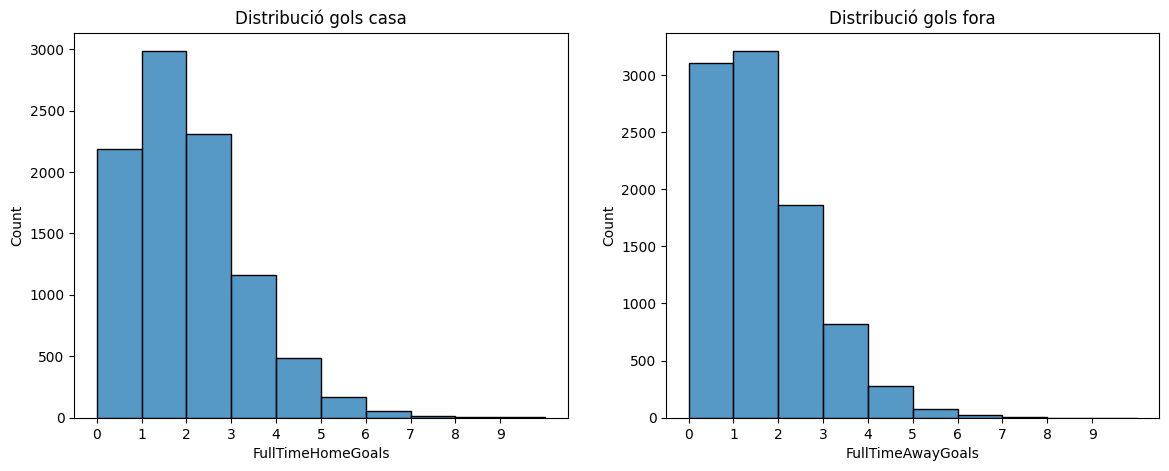

In [8]:
#4.EDA (Exploratory Data Analysis)
#---------------------------------
fig, ax = plt.subplots(1, 2, figsize=(14,5))

sns.histplot(df["FullTimeHomeGoals"], bins=range(0, df["FullTimeHomeGoals"].max()+2), ax=ax[0])
ax[0].set_title("Distribució gols casa")
ax[0].set_xticks(range(0, df["FullTimeHomeGoals"].max()+1))

sns.histplot(df["FullTimeAwayGoals"], bins=range(0, df["FullTimeAwayGoals"].max()+2), ax=ax[1])
ax[1].set_title("Distribució gols fora")
ax[1].set_xticks(range(0, df["FullTimeAwayGoals"].max()+1))

plt.show()

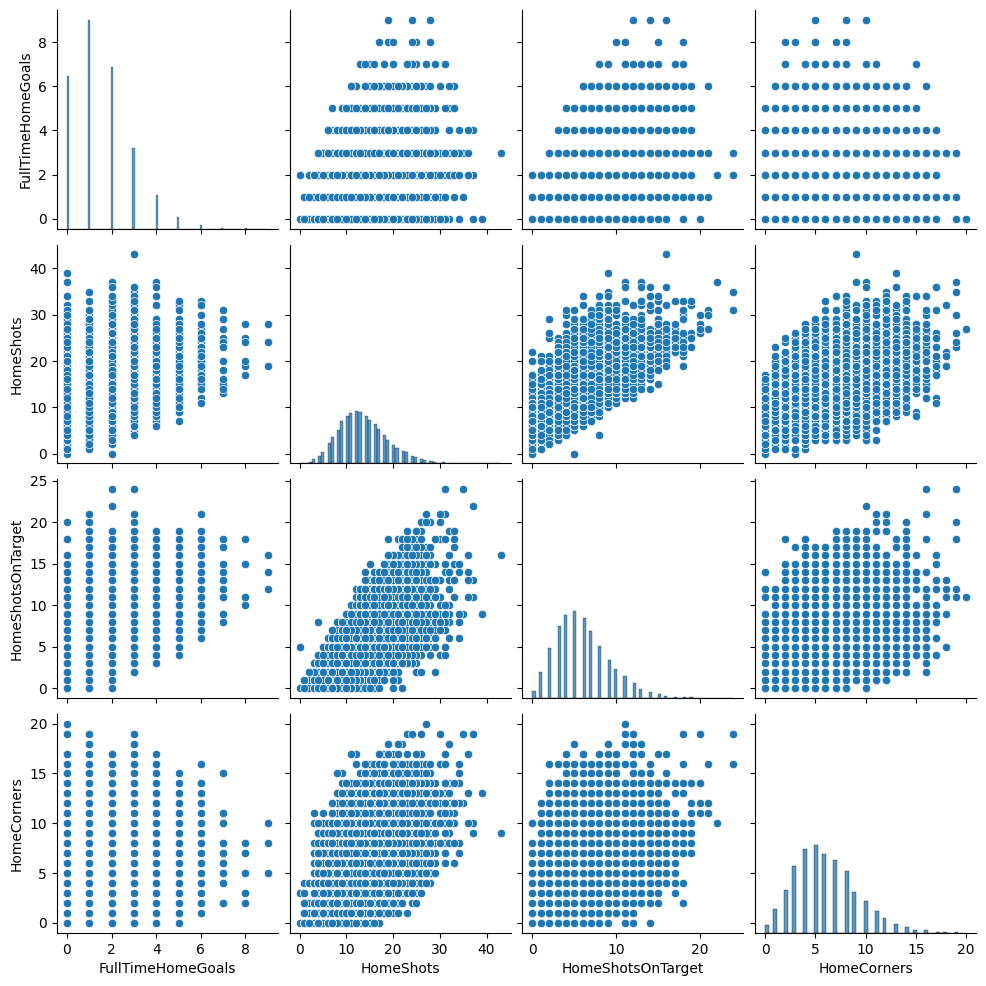

In [9]:
sns.pairplot(df[["FullTimeHomeGoals", "HomeShots", "HomeShotsOnTarget", "HomeCorners"]])
plt.show()
#Les distribucions mostren que els gols són baixos i esbiaixats, mentre que els tirs i tirs a porteria presenten més variabilitat.
#  S’observa una relació clara: com més tirs a porteria, més probabilitat de marcar, sent aquesta la correlació més forta del conjunt. 
# Els córners tenen una relació molt més feble amb els gols. En general, el gràfic indica que els **tirs a porteria** són el millor indicador de rendiment ofensiu 
# i probablement la característica més útil per al model predictiu.

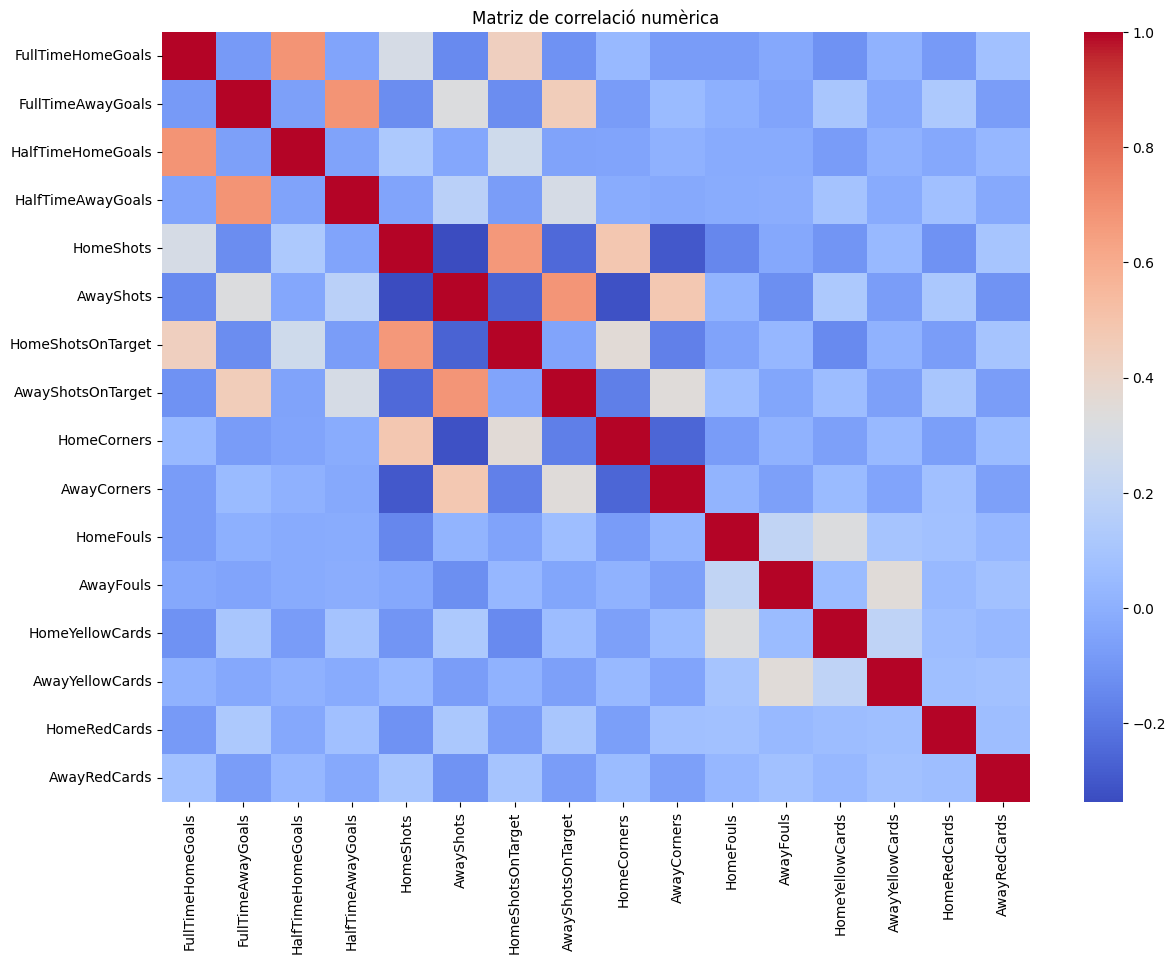

In [10]:
plt.figure(figsize=(14,10))
sns.heatmap(df.select_dtypes(include=np.number).corr(), cmap="coolwarm", annot=False)
plt.title("Matriz de correlació numèrica")
plt.show()
#matriu de correlacions

In [11]:
#5.Creació del dataset “long format” + rolling stats
#----------------------------------------------------

def add_team_rolling_stats_safe(df, n_list=[3,5,10]):
    df_sorted = df.sort_values("MatchDate").copy()

    # Mapeig esperat per a la part "home"
    home_map = {
        "MatchDate": "MatchDate",
        "Season": "Season",
        "HomeTeam": "Team",
        "AwayTeam": "Opponent",
        "FullTimeHomeGoals": "GoalsFor",
        "FullTimeAwayGoals": "GoalsAgainst",
        "HomeShots": "Shots",
        "HomeShotsOnTarget": "ShotsOnTarget",
        "HomeCorners": "Corners",
        "HomeFouls": "Fouls",
        "HomeYellowCards": "Yellow",
        "HomeRedCards": "Red"
    }

    # Trobar quines claus del mapeig existeixen realment al df
    home_cols_present = [col for col in home_map.keys() if col in df_sorted.columns]
    # Crear dataframe home amb només les columnes presents
    home = df_sorted[home_cols_present].copy()
    # Renombrar només les columnes presents
    home.rename(columns={k: home_map[k] for k in home_cols_present}, inplace=True)
    home["HomeAway"] = "H"

    # Mapeig per a la part "away" (simètric)
    away_map = {
        "MatchDate": "MatchDate",
        "Season": "Season",
        "AwayTeam": "Team",
        "HomeTeam": "Opponent",
        "FullTimeAwayGoals": "GoalsFor",
        "FullTimeHomeGoals": "GoalsAgainst",
        "AwayShots": "Shots",
        "AwayShotsOnTarget": "ShotsOnTarget",
        "AwayCorners": "Corners",
        "AwayFouls": "Fouls",
        "AwayYellowCards": "Yellow",
        "AwayRedCards": "Red"
    }

    away_cols_present = [col for col in away_map.keys() if col in df_sorted.columns]
    away = df_sorted[away_cols_present].copy()
    away.rename(columns={k: away_map[k] for k in away_cols_present}, inplace=True)
    away["HomeAway"] = "A"

    # Concatenar home + away
    long = pd.concat([home, away], ignore_index=True).sort_values(["Team", "MatchDate"]).reset_index(drop=True)

    # Assegurar que les columnes GoalsFor/GoalsAgainst existeixen (si no, crear-les amb 0)
    if "GoalsFor" not in long.columns:
        long["GoalsFor"] = 0
    if "GoalsAgainst" not in long.columns:
        long["GoalsAgainst"] = 0

    long["GoalDiff"] = long["GoalsFor"] - long["GoalsAgainst"]
    long["Points"] = long["GoalDiff"].apply(lambda x: 3 if x > 0 else (1 if x == 0 else 0))

    # Aplicar rolling només a les columnes que existeixen i són numèriques
    numeric_candidates = ["GoalsFor", "GoalsAgainst", "Shots", "ShotsOnTarget", "Corners", "Fouls", "Yellow", "Red", "Points"]
    numeric_present = [c for c in numeric_candidates if c in long.columns]

    for n in n_list:
        for col in numeric_present:
            roll_col_name = f"{col}_roll_{n}"
            # groupby rolling per equip
            long[roll_col_name] = long.groupby("Team")[col].rolling(n, min_periods=1).mean().reset_index(0, drop=True)

    return long

# Executar la funció corregida
long = add_team_rolling_stats_safe(df, n_list=[3,5,10])
long.head()


,MatchDate,Season,Team,Opponent,GoalsFor,GoalsAgainst,Shots,ShotsOnTarget,Corners,Fouls,...,Points_roll_5,GoalsFor_roll_10,GoalsAgainst_roll_10,Shots_roll_10,ShotsOnTarget_roll_10,Corners_roll_10,Fouls_roll_10,Yellow_roll_10,Red_roll_10,Points_roll_10
0,2000-08-19,2000/01,Arsenal,Sunderland,0,1,14,7,9,21,...,0.00,0.000000,1.000000,14.000000,7.000000,9.00,21.000000,1.0,1.000000,0.00
1,2000-08-21,2000/01,Arsenal,Liverpool,2,0,17,12,10,25,...,1.50,1.000000,0.500000,15.500000,9.500000,9.50,23.000000,1.5,1.000000,1.50
2,2000-08-26,2000/01,Arsenal,Charlton,5,3,18,9,8,12,...,2.00,2.333333,1.333333,16.333333,9.333333,9.00,19.333333,1.0,0.666667,2.00
3,2000-09-06,2000/01,Arsenal,Chelsea,2,2,13,5,6,22,...,1.75,2.250000,1.500000,15.500000,8.250000,8.25,20.000000,1.0,0.500000,1.75
4,2000-09-09,2000/01,Arsenal,Bradford,1,1,18,11,10,13,...,1.60,2.000000,1.400000,16.000000,8.800000,8.60,18.600000,1.2,0.400000,1.60


In [12]:
def build_match_features(df, long):

    home_stats = long[long["HomeAway"]=="H"].copy().add_prefix("home_")
    away_stats = long[long["HomeAway"]=="A"].copy().add_prefix("away_")

    m = df.copy()

    m = m.merge(home_stats, left_on=["HomeTeam","MatchDate"],
                right_on=["home_Team","home_MatchDate"], how="left")

    m = m.merge(away_stats, left_on=["AwayTeam","MatchDate"],
                right_on=["away_Team","away_MatchDate"], how="left")

    m["Shots_diff"] = m["home_Shots"] - m["away_Shots"]
    m["SoT_diff"]   = m["home_ShotsOnTarget"] - m["away_ShotsOnTarget"]

    return m

M = build_match_features(df, long)
M.head()
#build_match_features converteix 2 files (estatístiques separades de cada equip) en 1 sola fila amb TOTA la informació combinada del partit, incloent diferències 
# numèriques molt útils per predir resultats.


,Season,MatchDate,HomeTeam,AwayTeam,FullTimeHomeGoals,FullTimeAwayGoals,FullTimeResult,HalfTimeHomeGoals,HalfTimeAwayGoals,HalfTimeResult,...,away_GoalsAgainst_roll_10,away_Shots_roll_10,away_ShotsOnTarget_roll_10,away_Corners_roll_10,away_Fouls_roll_10,away_Yellow_roll_10,away_Red_roll_10,away_Points_roll_10,Shots_diff,SoT_diff
0,2000/01,2000-08-19,Charlton,Man City,4,0,H,2,0,H,...,4.0,8.0,4.0,6.0,12.0,2.0,0.0,0.0,9,10
1,2000/01,2000-08-19,Chelsea,West Ham,4,2,H,1,0,H,...,4.0,12.0,5.0,7.0,14.0,2.0,0.0,0.0,5,5
2,2000/01,2000-08-19,Coventry,Middlesbrough,1,3,A,1,1,D,...,1.0,16.0,9.0,4.0,21.0,3.0,0.0,3.0,-10,-6
3,2000/01,2000-08-19,Derby,Southampton,2,2,D,1,2,A,...,2.0,13.0,6.0,8.0,13.0,1.0,0.0,1.0,-7,-2
4,2000/01,2000-08-19,Leeds,Everton,2,0,H,2,0,H,...,2.0,12.0,6.0,4.0,20.0,3.0,0.0,0.0,5,2


In [13]:
#6.Preparació del dataset per al model final
#--------------------------------------------

# 1. Ens quedem NOMÉS amb estadístiques importants + info bàsica
cols_excluded = [
    "GoalsFor", "GoalsAgainst", "GoalDiff", "Points",
    "Shots", "ShotsOnTarget", "Corners", "Fouls", "Yellow", "Red"
]

# Columnes importants (les bones)
roll_cols = [c for c in long.columns if "roll_" in c]

# Variables d'entrada
feature_cols = ["Team", "Opponent", "HomeAway", "Season", "MatchDate"] + roll_cols

# Eliminem qualsevol resultat d'entrada
feature_cols = [c for c in feature_cols if c in long.columns]

X = long[feature_cols].copy()

# 2. Variable objectiu → Resultat del partit original
# Necessitem fer un merge amb df original per recuperar FullTimeResult
df_result = df[["MatchDate", "HomeTeam", "AwayTeam", "FullTimeResult"]].copy()

# Assignem quin equip és cada fila del long-format
merged = long.merge(df_result,
                    left_on=["MatchDate", "Team", "Opponent"],
                    right_on=["MatchDate", "HomeTeam", "AwayTeam"],
                    how="left")

merged2 = long.merge(df_result,
                    left_on=["MatchDate", "Opponent", "Team"],
                    right_on=["MatchDate", "HomeTeam", "AwayTeam"],
                    how="left")

merged["FT"] = merged["FullTimeResult"]
merged.loc[merged["FT"].isna(), "FT"] = merged2["FullTimeResult"]

# Variable objectiu final
y = merged["FT"]

# 3. EL PAS IMPORTANT: ordenar per data (obligatori!)
ordered = merged.sort_values("MatchDate")

X = ordered[feature_cols]
y = ordered["FT"]

# 4. Train-test split per data (simulem futur)
cut = int(len(X) * 0.8)
X_train, X_test = X.iloc[:cut], X.iloc[cut:]
y_train, y_test = y.iloc[:cut], y.iloc[cut:]

print("Mides:")
print("Train:", X_train.shape)
print("Test:", X_test.shape)

#Aquest codi prepara les dades per predir resultats de futbol evitant data leakage. Es seleccionen només les variables disponibles abans del partit,
#  s’assigna correctament la variable objectiu segons l’equip local o visitant, i s’ordenen els partits cronològicament. Finalment, es fa un train-test split temporal, 
# assegurant que el model només aprengui de la informació prèvia als partits.



Mides:
Train: (15008, 32)
Test: (3752, 32)


In [14]:
#7.Model principal (RandomForestClassifier)
#------------------------------------------
num_cols = [c for c in X_train.columns if "roll_" in c]   # només stats rollants
cat_cols = ["Team", "Opponent", "HomeAway", "Season"]     # categoricals útils

# Confirmem que totes existeixen
cat_cols = [c for c in cat_cols if c in X_train.columns]
num_cols = [c for c in num_cols if c in X_train.columns]

print("Columnes numèriques:", len(num_cols))
print("Columnes categòriques:", len(cat_cols))

# 2. Preprocessament
preprocess = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
    ]
)

# 3. Model (Random Forest per defecte, funciona molt bé en futbol)
model = RandomForestClassifier(
    n_estimators=400,
    max_depth=None,
    random_state=42,
    class_weight="balanced"
)

# 4. Pipeline
pipe = Pipeline(steps=[
    ("prep", preprocess),
    ("model", model)
])

# 5. Entrenament
pipe.fit(X_train, y_train)

# 6. Prediccions
y_pred = pipe.predict(X_test)

# 7. Mètriques
acc = accuracy_score(y_test, y_pred)
print("=======================================")
print(" ACCURACY DEL MODEL")
print("=======================================")
print(f"Accuracy: {acc:.4f}")

print("\n=======================================")
print(" CLASSIFICATION REPORT")
print("=======================================")
print(classification_report(y_test, y_pred))
#Aquest codi crea un model de predicció de resultats de futbol combinant preprocessament i Random Forest en un pipeline.
# 4 Primer, es seleccionen les columnes numèriques (estadístiques rollants) i categòriques (equip local, visitant, temporada i tipus de partit). 
# Les variables numèriques es normalitzen i les categòriques es codifiquen amb one-hot encoding. 
# A continuació, s’entrena un `RandomForestClassifier` amb arbres balancejats sobre el conjunt d’entrenament i es fan prediccions sobre el conjunt de test. 
# Finalment, s’avalua el rendiment del model amb *accuracy* i un informe de classificació que mostra precision, recall i f1-score per cada resultat possible del partit.


Columnes numèriques: 27
Columnes categòriques: 4
 ACCURACY DEL MODEL
Accuracy: 0.6354

 CLASSIFICATION REPORT
              precision    recall  f1-score   support

           A       0.68      0.60      0.64      1268
           D       0.54      0.22      0.31       859
           H       0.63      0.88      0.73      1625

    accuracy                           0.64      3752
   macro avg       0.62      0.57      0.56      3752
weighted avg       0.63      0.64      0.61      3752



In [15]:
# 8.Interpretabilitat (feature importance)
# -------------------------------

# Extraiem el model i el preprocesador del pipeline
clf = pipe.named_steps["model"]
preprocessor = pipe.named_steps["prep"]

# Extraiem el OneHotEncoder de les columnes categòriques
ohe = preprocessor.named_transformers_["cat"]

# Obtenim automàticament els noms de les columnes codificades
cat_names = ohe.get_feature_names_out()  # no cal passar res, agafa les columnes ajustades

# Combinem amb les columnes numèriques
feature_names = num_cols + list(cat_names)

# Importància de les característiques
importances = clf.feature_importances_

# Creem un DataFrame amb els resultats
imp_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

# Mostrem les 20 característiques més importants
imp_df.head(20)


,feature,importance
8,Points_roll_3,0.082451
113,HomeAway_A,0.044837
114,HomeAway_H,0.044171
17,Points_roll_5,0.035515
20,Shots_roll_10,0.031200
23,Fouls_roll_10,0.030662
1,GoalsAgainst_roll_3,0.030113
21,ShotsOnTarget_roll_10,0.029797
22,Corners_roll_10,0.029551
11,Shots_roll_5,0.029402


<Figure size 1000x1200 with 0 Axes>

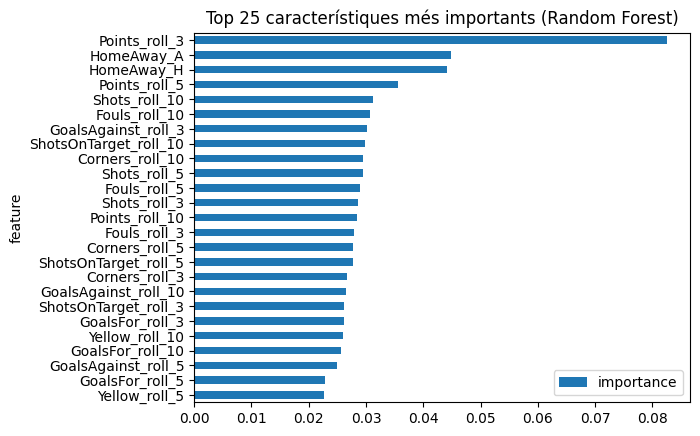

In [16]:
# Importàncies
importances = clf.feature_importances_

imp_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

# Gràfic
plt.figure(figsize=(10, 12))
imp_df.head(25).plot(kind="barh", x="feature", y="importance")
plt.title("Top 25 característiques més importants (Random Forest)")
plt.gca().invert_yaxis()
plt.show()

In [17]:
#9.Models auxiliars: regressió de gols, punts, xG
#-------------------------------------------------

num_cols = [c for c in X.columns if "roll_" in c]
cat_cols = ["Team", "Opponent", "HomeAway", "Season"]
cat_cols = [c for c in cat_cols if c in X.columns]

preproc = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])


X_home = X.loc[M.index]   # coincideix amb les files de M
y_home = M["FullTimeHomeGoals"]


pipe_reg = Pipeline([
    ("pre", preproc),
    ("reg", RandomForestRegressor(
        n_estimators=100,   # menys arbres → més ràpid
        random_state=42,
        n_jobs=-1           # usa tots els nuclis del CPU
    ))
])


Xtr_h, Xte_h, ytr_h, yte_h = train_test_split(
    X_home, y_home, test_size=0.2, random_state=42
)


pipe_reg.fit(Xtr_h, ytr_h)


pred_h = pipe_reg.predict(Xte_h)


rmse = np.sqrt(mean_squared_error(yte_h, pred_h))  # arrel quadrada manual
mae = mean_absolute_error(yte_h, pred_h)
r2 = r2_score(yte_h, pred_h)

print("======================================")
print("   MÈTRIQUES – GOLS CASA")
print("======================================")
print(f"RMSE: {rmse:.3f}")
print(f"MAE:  {mae:.3f}")
print(f"R²:   {r2:.3f}")
#Aquest codi complementa el model de classificació anterior, però ara prediu **el nombre de gols de l’equip local.
#S’utilitzen les mateixes estadístiques rollants i variables categòriques, amb un Random Forest més ràpid per generar prediccions de manera eficient 
# i avaluar-les amb RMSE, MAE i R².

   MÈTRIQUES – GOLS CASA
RMSE: 1.330
MAE:  1.057
R²:   -0.025


In [18]:
# Hem escollit entrenar el Random Forest amb 100 arbres (n_estimators=100) per les següents raons:
# Rendiment: amb 100 arbres, el model ja és prou robust per a un dataset de ~9000 files, 
#    i l'entrenament és molt més ràpid que amb 300 o més arbres.
# Precisió: augmentar més arbres aporta una millora mínima en RMSE o R², 
#    per la qual cosa no compensa el temps addicional d'entrenament.
# Experimentació: 100 arbres permet provar ràpidament el pipeline, depurar i ajustar 
#    altres paràmetres sense esperar massa temps.
# Recomanació: 100 arbres és un bon compromís entre precisió i rapidesa; 
#    per la versió final, si es vol maximitzar la precisió, es podria augmentar el nombre d’arbres.

In [19]:
X_xg = M[["home_Shots", "home_ShotsOnTarget", "home_Corners"]].fillna(0)
y_xg = M["FullTimeHomeGoals"]

pipe_xg = Pipeline([
    ("sc", StandardScaler()),
    ("pr", PoissonRegressor(alpha=0.1, max_iter=300))
])

mask = X_xg.notnull().all(axis=1)
pipe_xg.fit(X_xg[mask], y_xg[mask])

M["xG_home_proxy"] = pipe_xg.predict(X_xg)
M[["FullTimeHomeGoals","xG_home_proxy"]].head()
#Calculem els gols esperats, reals i esperats (PoissonRegressor) de l’equip local basant-nos en tirs, tirs a porteria i córners.

,FullTimeHomeGoals,xG_home_proxy
0,4,3.188687
1,4,2.123337
2,1,0.931376
3,2,1.138974
4,2,1.829398


In [20]:

M["PointsHome"] = M["FullTimeResult"].map({"H":3, "D":1, "A":0})
y_pts = M["PointsHome"]
X_pts = X.loc[M.index]   # assegura que X i y tinguin el mateix nombre de files


pipe_pts = Pipeline([
    ("pre", preproc),
    ("reg", RandomForestRegressor(
        n_estimators=100,   # menys arbres → més ràpid
        random_state=42,
        n_jobs=-1           # usa tots els nuclis del CPU
    ))
])


Xtr_p, Xte_p, ytr_p, yte_p = train_test_split(
    X_pts, y_pts, test_size=0.2, random_state=42
)


pipe_pts.fit(Xtr_p, ytr_p)


pred_p = pipe_pts.predict(Xte_p)


rmse = np.sqrt(mean_squared_error(yte_p, pred_p))  # arrel quadrada manual
mae = mean_absolute_error(yte_p, pred_p)
r2 = r2_score(yte_p, pred_p)

print("======================================")
print("   MÈTRIQUES – PUNTS CASA")
print("======================================")
print(f"RMSE: {rmse:.3f}")
print(f"MAE:  {mae:.3f}")
print(f"R²:   {r2:.3f}")


   MÈTRIQUES – PUNTS CASA
RMSE: 1.340
MAE:  1.267
R²:   -0.032


In [21]:
df_clf = df.copy()

X_clf = df_clf[['HomeShotsOnTarget','AwayShotsOnTarget']]
y_clf = df_clf['FullTimeResult']   # H / D / A

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

clf = RandomForestClassifier(n_estimators=400, random_state=42)
clf.fit(Xc_train, yc_train)

yhat = clf.predict(Xc_test)

print("=== CLASSIFICATION REPORT ===")
print(classification_report(yc_test, yhat))
print("Accuracy:", accuracy_score(yc_test, yhat))

# Funció: calcular probabilitats H/D/A a partir de tirs a porta
def prob_HDA_from_shots_ml(classifier, home_sot, away_sot):
    X_new = pd.DataFrame([[home_sot, away_sot]],
                          columns=['HomeShotsOnTarget','AwayShotsOnTarget'])
    probs = classifier.predict_proba(X_new)[0]
    classes = classifier.classes_
    return dict(zip(classes, probs))


=== CLASSIFICATION REPORT ===
              precision    recall  f1-score   support

           A       0.50      0.57      0.53       554
           D       0.31      0.08      0.13       462
           H       0.60      0.78      0.68       860

    accuracy                           0.55      1876
   macro avg       0.47      0.48      0.45      1876
weighted avg       0.50      0.55      0.50      1876

Accuracy: 0.5463752665245203


In [22]:
# Definició correcta del dataset per al regressor xG_home

df_reg = df.copy()

XR_home = df_reg[['HomeShots','HomeShotsOnTarget']]
yR_home = df_reg['FullTimeHomeGoals']
Xr_home_train, Xr_home_test, yr_home_train, yr_home_test = train_test_split(
    XR_home, yR_home, test_size=0.2, random_state=42
)
reg_home = RandomForestRegressor(n_estimators=300, random_state=42)
reg_home.fit(Xr_home_train, yr_home_train)

pois_home = PoissonRegressor(alpha=0.1, max_iter=300)
pois_home.fit(Xr_home_train, yr_home_train)


,alpha,0.1
,fit_intercept,True
,solver,'lbfgs'
,max_iter,300
,tol,0.0001
,warm_start,False
,verbose,0


In [23]:
print("=== Importància del classificador ===")
imp_clf = permutation_importance(clf, Xc_test, yc_test,
                                 n_repeats=20, random_state=42)
imp_df_clf = pd.DataFrame({
    'feature': Xc_test.columns,
    'importance': imp_clf.importances_mean
}).sort_values('importance', ascending=False)
print(imp_df_clf)

print("\n=== Importància del regressor (xG home) ===")
imp_reg = permutation_importance(reg_home, Xr_home_test, yr_home_test,
                                 n_repeats=20, random_state=42)
imp_df_reg = pd.DataFrame({
    'feature': Xr_home_test.columns,
    'importance': imp_reg.importances_mean
}).sort_values('importance', ascending=False)
print(imp_df_reg)


=== Importància del classificador ===
             feature  importance
0  HomeShotsOnTarget    0.085048
1  AwayShotsOnTarget    0.071455

=== Importància del regressor (xG home) ===
             feature  importance
1  HomeShotsOnTarget    0.440987
0          HomeShots    0.022321


In [24]:
#10.Funcions analítiques (probabilitat de victòria)
#-------------------------------------------------------

def win_probability_ml(reg_home, reg_away, clf, shots_range=range(0,21)):
    idx_H = list(clf.classes_).index("H")

    probs_home = []
    probs_away = []

    for shots in shots_range:

        # Predecimos goles esperados con los regresores
        Xh = pd.DataFrame([[shots]], columns=["ShotsOnTarget"])
        Xa = pd.DataFrame([[10]],    columns=["ShotsOnTarget"])  # valor fijo, como hacías antes

        gh = reg_home.predict(Xh)[0]
        ga = reg_away.predict(Xa)[0]

        # Clasificador: ¡usar nombres correctos!
        X_cls = pd.DataFrame([[gh, ga]],
                             columns=["FullTimeHomeGoals", "FullTimeAwayGoals"])

        pH_home = clf.predict_proba(X_cls)[0][idx_H]
        probs_home.append(pH_home)


        # intercambiamos
        X_cls2 = pd.DataFrame([[ga, gh]],
                              columns=["FullTimeHomeGoals", "FullTimeAwayGoals"])

        pH_away = clf.predict_proba(X_cls2)[0][idx_H]
        probs_away.append(pH_away)

    df_home = pd.DataFrame({"ShotsOnTarget": shots_range, "Probability_H": probs_home})
    df_away = pd.DataFrame({"ShotsOnTarget": shots_range, "Probability_H": probs_away})

    return df_home, df_away


In [25]:
def plot_win_probability_ml(reg_home, reg_away, clf):
    shots_range = range(0,21)
    df_home, df_away = win_probability_ml(reg_home, reg_away, clf, shots_range)

    plt.figure(figsize=(12,6))
    plt.plot(df_home["ShotsOnTarget"], df_home["Probability_H"], label="Casa", marker='o')
    plt.plot(df_away["ShotsOnTarget"], df_away["Probability_H"], label="Fuera", marker='s')

    plt.axhline(0.5, color='gray', linestyle='--', alpha=0.5)
    plt.xlabel("Tiros a puerta")
    plt.ylabel("Probabilidad de victoria (H)")
    plt.title("Probabilidad de ganar según tiros a puerta (Modelo ML)")
    plt.legend()
    plt.grid(True)
    plt.show()


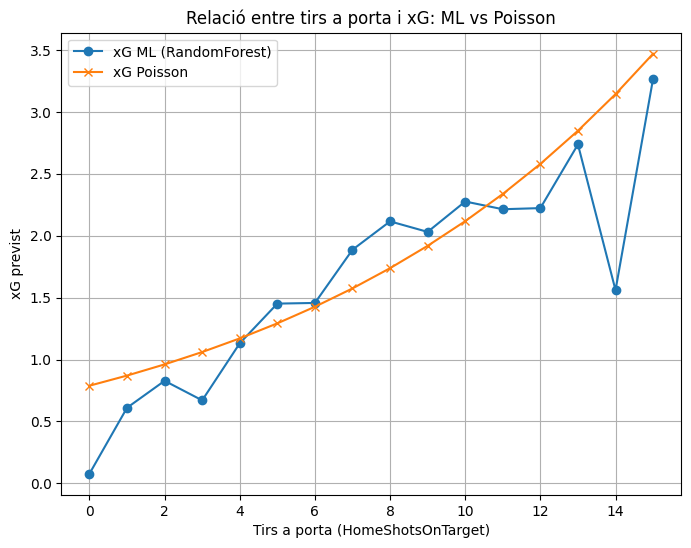

In [26]:


XR_home = df[['HomeShots','HomeShotsOnTarget']]
yR_home = df['FullTimeHomeGoals']

X_train, X_test, y_train, y_test = train_test_split(
    XR_home, yR_home, test_size=0.2, random_state=42
)

# Models
reg_home = RandomForestRegressor(n_estimators=300, random_state=42)
reg_home.fit(X_train, y_train)

pois_home = PoissonRegressor(alpha=0.1, max_iter=300)
pois_home.fit(X_train, y_train)

# --- Grafic relacionat amb l’anàlisi ---
# xG segons tirs a porta
shots_on_target = np.arange(0, 16)

X_curve = pd.DataFrame({
    "HomeShots": shots_on_target + 3,   # relació típica: tirs > tirs a porta
    "HomeShotsOnTarget": shots_on_target
})

xg_ml = reg_home.predict(X_curve)
xg_pois = pois_home.predict(X_curve)

plt.figure(figsize=(8,6))
plt.plot(shots_on_target, xg_ml, marker="o", label="xG ML (RandomForest)")
plt.plot(shots_on_target, xg_pois, marker="x", label="xG Poisson")

plt.xlabel("Tirs a porta (HomeShotsOnTarget)")
plt.ylabel("xG previst")
plt.title("Relació entre tirs a porta i xG: ML vs Poisson")
plt.grid(True)
plt.legend()
plt.show()


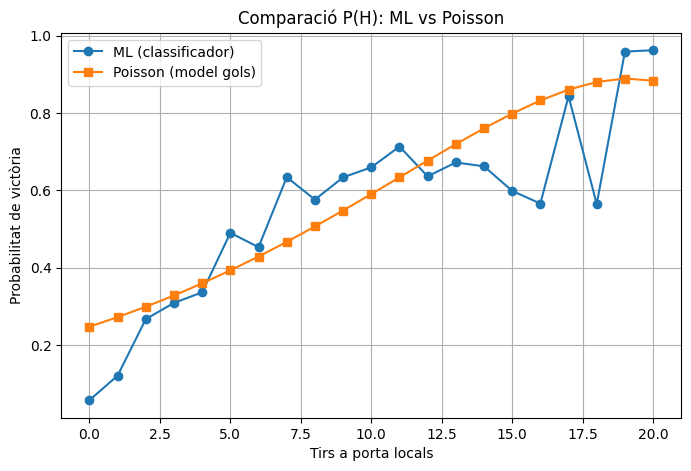

,ShotsOnTarget,P(H)_ML,P(H)_Poisson
0,0,0.057583,0.247604
1,1,0.121303,0.272350
2,2,0.267392,0.299227
3,3,0.309161,0.328310
4,4,0.336453,0.359642


In [27]:
#11.Comparació ML vs Poisson en forma de gràfic
#-----------------------------------------------

shots_range = range(0, 21)
ph_ml, ph_pois = [], []

# Rival fix (tirs a porta)
away_fixed = int(df['AwayShotsOnTarget'].median())

for sot in shots_range:

    # ---- 1) xG ML ----
    X_ml = pd.DataFrame([[sot, away_fixed]],
                        columns=['HomeShotsOnTarget','AwayShotsOnTarget'])
    # xG ML no s'usa pel classificador, només es guarda si vols comparar
    # xg_ml = reg_home.predict(pd.DataFrame([[sot+3, sot]], 
    #                     columns=['HomeShots','HomeShotsOnTarget']))[0]

    # ---- 2) xG Poisson ----
    # xg_pois = pois_home.predict(pd.DataFrame([[sot+3, sot]],
    #                     columns=['HomeShots','HomeShotsOnTarget']))[0]

    # ---- 3) Prob ML (classificador) ----
    probs_ml = clf.predict_proba(X_ml)[0]
    pH_ml = probs_ml[clf.classes_.tolist().index('H')]
    ph_ml.append(pH_ml)

    # ---- 4) Prob Poisson (Poisson és regressió, no classificador)
    # Per fer P(H) amb Poisson:
    #    - Estimem xGHome Poisson
    #    - Estimem xGAway Poisson (fixa)
    #    - Calculem distribució de gols locals vs visitants
    #    - Sumem P(goals_home > goals_away)

    # xG home via Poisson
    xg_home = pois_home.predict(pd.DataFrame([[sot+3, sot]],
                        columns=['HomeShots','HomeShotsOnTarget']))[0]

    # xG away: assumim constant pels tirs del rival
    xg_away = pois_home.predict(pd.DataFrame([[away_fixed+3, away_fixed]],
                        columns=['HomeShots','HomeShotsOnTarget']))[0]

    # Prob H via distribució Poisson
    from scipy.stats import poisson

    max_goals = 10
    P_H = 0
    for hg in range(max_goals):
        for ag in range(max_goals):
            if hg > ag:
                P_H += poisson.pmf(hg, xg_home) * poisson.pmf(ag, xg_away)

    ph_pois.append(P_H)

# ---- GRÀFIC FINAL ----
plt.figure(figsize=(8,5))
plt.plot(shots_range, ph_ml, marker='o', label="ML (classificador)")
plt.plot(shots_range, ph_pois, marker='s', label="Poisson (model gols)")
plt.xlabel("Tirs a porta locals")
plt.ylabel("Probabilitat de victòria")
plt.title("Comparació P(H): ML vs Poisson")
plt.grid(True)
plt.legend()
plt.show()

# Resultats en taula
comparison_df = pd.DataFrame({
    'ShotsOnTarget': shots_range,
    'P(H)_ML': ph_ml,
    'P(H)_Poisson': ph_pois
})

comparison_df.head()


In [28]:
#11.Clustering d’equips per temporada (KMeans)
agg = long.groupby(["Team","Season"]).agg({
    "Shots":"mean",
    "ShotsOnTarget":"mean",
    "Corners":"mean",
    "GoalsFor":"mean",
    "GoalsAgainst":"mean"
}).reset_index().fillna(0)

features = ["Shots","ShotsOnTarget","Corners","GoalsFor","GoalsAgainst"]
kmeans = KMeans(n_clusters=4, random_state=42)
agg["cluster"] = kmeans.fit_predict(agg[features])

agg[agg["Team"]=="Arsenal"]
#Aquest codi agrupa els equips per temporada i els classifica en 4 clusters segons les seves estadístiques mitjanes de tirs, 
# tirs a porteria, córners i gols a favor i en contra. L’objectiu és identificar patrons de rendiment similar entre equips, de manera que equips amb ofensiva
#  i defensa semblants quedin en el mateix grup, facilitant l’anàlisi comparativa i la detecció de perfils tàctics.
#Ens quedem amb el arsenal
#Ens ajuda a saber el comportament del arsenal aquella temporada
# El cluster 1 representa temporades amb atac intens i molts tirs; 
# cluster 2, equips equilibrats amb ofensiva i defensa sòlides; 
# cluster 3, períodes menys dominants però efectius; 
#cluster 0, temporades més febles amb menys ocasions i gols. 


,Team,Season,Shots,ShotsOnTarget,Corners,GoalsFor,GoalsAgainst,cluster
0,Arsenal,2000/01,14.210526,7.763158,7.763158,1.657895,1.000000,1
1,Arsenal,2001/02,13.631579,6.868421,6.473684,2.078947,0.947368,2
2,Arsenal,2002/03,13.105263,7.789474,7.000000,2.236842,1.105263,2
3,Arsenal,2003/04,12.393939,7.212121,5.424242,1.848485,0.696970,2
4,Arsenal,2004/05,12.666667,8.060606,5.818182,2.212121,1.000000,2
5,Arsenal,2005/06,12.157895,7.210526,5.552632,1.789474,0.815789,2
6,Arsenal,2006/07,14.131579,7.263158,7.315789,1.657895,0.921053,1
7,Arsenal,2007/08,13.947368,7.605263,6.236842,1.947368,0.815789,2
8,Arsenal,2008/09,14.578947,8.315789,7.052632,1.789474,0.973684,1
9,Arsenal,2009/10,14.736842,8.657895,6.789474,2.184211,1.078947,1


In [29]:
# Ignorar warnings de convergència del Poisson
warnings.filterwarnings("ignore", category=ConvergenceWarning)

def min_shots_to_win(pipe_xg, threshold=0.6, max_shots=20, away_avg_goals=1.1):
    """
    Calcula el mínim nombre de tirs a porteria per assolir una probabilitat de victòria >= threshold.
    """
    # Noms de les columnes que el model espera
    col_names = ["home_Shots", "home_ShotsOnTarget", "home_Corners"]
    
    for shots_on_target in range(1, max_shots+1):
        # Creem un DataFrame amb els noms correctes
        X_new = pd.DataFrame([[shots_on_target, shots_on_target, 0]], columns=col_names)
        
        # Gols esperats amb aquests tirs
        mu_home = pipe_xg.predict(X_new)[0]
        
        # Probabilitat de guanyar
        p_win = 0
        for gh in range(0, 11):
            for ga in range(0, 11):
                if gh > ga:
                    p_win += poisson.pmf(gh, mu_home) * poisson.pmf(ga, away_avg_goals)
        
        if p_win >= threshold:
            return shots_on_target, p_win
    
    # Si no arriba al threshold amb max_shots
    return max_shots, p_win

# Exemple d'ús
shots_needed, prob = min_shots_to_win(pipe_xg, threshold=0.6)
print(f"Tirs necessaris: {shots_needed}, Probabilitat H: {prob:.2f}")


Tirs necessaris: 9, Probabilitat H: 0.63


In [30]:
def season_table(df, season):
    s = df[df["Season"]==season].copy()

    s["PointsHome"] = s["FullTimeResult"].map({"H":3,"D":1,"A":0})
    s["PointsAway"] = s["FullTimeResult"].map({"A":3,"D":1,"H":0})

    home = s.groupby("HomeTeam")["PointsHome"].sum().reset_index().rename(columns={"HomeTeam":"Team"})
    away = s.groupby("AwayTeam")["PointsAway"].sum().reset_index().rename(columns={"AwayTeam":"Team"})

    # Sumem els punts de casa i fora
    table = pd.concat([home, away])
    table = table.groupby("Team")[["PointsHome","PointsAway"]].sum()  # ara correctament amb llista
    table["Points"] = table["PointsHome"] + table["PointsAway"]
    table = table[["Points"]].reset_index()

    return table.sort_values("Points", ascending=False)


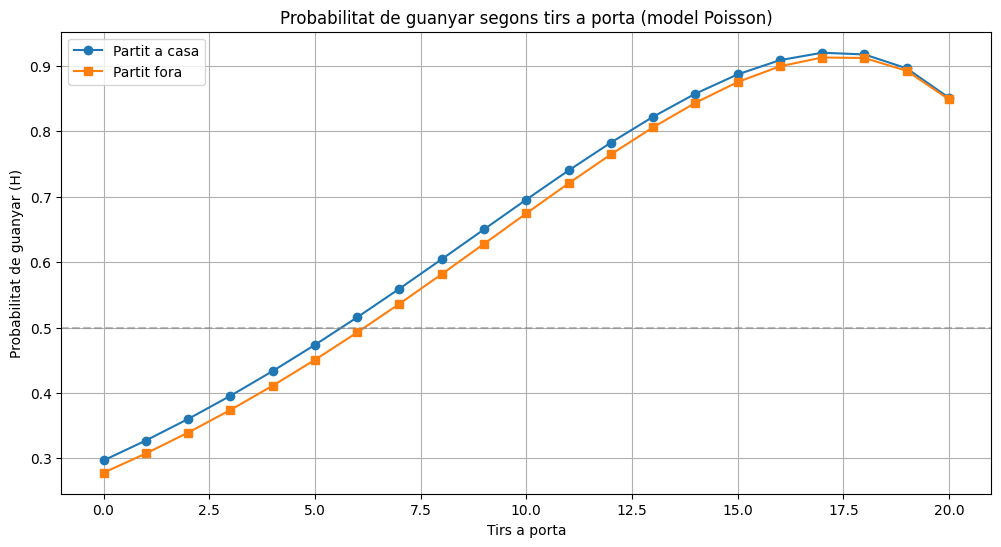

In [31]:
#12.Comparacio de models i resultats
def win_probability_poisson(pipe_xg, shots_range=range(0,21), home_avg_goals=1.1, away_avg_goals=1.1):
    """
    Calcula la probabilitat de guanyar segons tirs a porta utilitzant el model Poisson.
    Retorna dos DataFrames: casa i fora.
    """
    col_names = ["home_Shots", "home_ShotsOnTarget", "home_Corners"]
    
    # Partit a casa
    probs_home = []
    for shots_on_target in shots_range:
        X_new = pd.DataFrame([[shots_on_target + 3, shots_on_target, 0]], columns=col_names)
        mu_home = pipe_xg.predict(X_new)[0]
        p_win = 0
        for gh in range(0,11):
            for ga in range(0,11):
                if gh > ga:
                    p_win += poisson.pmf(gh, mu_home) * poisson.pmf(ga, away_avg_goals)
        probs_home.append(p_win)
    
    df_home = pd.DataFrame({
        "ShotsOnTarget": list(shots_range),
        "Probability_H": probs_home
    })

    # Partit fora
    probs_away = []
    for shots_on_target in shots_range:
        X_new = pd.DataFrame([[shots_on_target + 3, shots_on_target, 0]], columns=col_names)
        mu_away = pipe_xg.predict(X_new)[0]
        p_win = 0
        for gh in range(0,11):
            for ga in range(0,11):
                if gh > ga:
                    p_win += poisson.pmf(gh, mu_away) * poisson.pmf(ga, home_avg_goals)
        probs_away.append(p_win)

    df_away = pd.DataFrame({
        "ShotsOnTarget": list(shots_range),
        "Probability_H": probs_away
    })
    
    return df_home, df_away


def plot_win_probability_poisson(pipe_xg, home_avg_goals=1.1, away_avg_goals=1.1):
    """
    Genera gráfico con probabilidades de ganar para partidos en casa y fuera.
    """
    shots_range = range(0,21)
    df_home, df_away = win_probability_poisson(pipe_xg, shots_range, home_avg_goals, away_avg_goals)
    
    plt.figure(figsize=(12,6))
    plt.plot(df_home["ShotsOnTarget"], df_home["Probability_H"], label="Partit a casa", marker='o')
    plt.plot(df_away["ShotsOnTarget"], df_away["Probability_H"], label="Partit fora", marker='s')
    plt.axhline(0.5, color='gray', linestyle='--', alpha=0.5)
    plt.xlabel("Tirs a porta")
    plt.ylabel("Probabilitat de guanyar (H)")
    plt.title("Probabilitat de guanyar segons tirs a porta (model Poisson)")
    plt.legend()
    plt.grid(True)
    plt.show()


# Exemple d'ús:
plot_win_probability_poisson(pipe_xg, home_avg_goals=1.2, away_avg_goals=1.1)


In [32]:
seasons = df["Season"].unique()
champ_points, releg_points = [], []

for s in seasons:
    t = season_table(df, s)
    champ_points.append(t.iloc[0]["Points"])
    releg_points.append(t.iloc[-1]["Points"])

print("Mitjana punts campió:", np.mean(champ_points))
print("Mitjana punts descens:", np.mean(releg_points))


Mitjana punts campió: 87.8
Mitjana punts descens: 23.56


In [33]:
#13.Conclusions finals
#-----------------------

print("""
CONCLUSIONS PER L'ARSENAL

1) Les variables que més afecten la victòria segons el model:
   - Tirs a porteria
   - Diferència de tirs (SoT_diff)
   - Forma recent GF_roll_5
   - Corners

2) Llindars recomanats:
   - ≥ 6 tirs a porteria → probabilitat de victòria > 60%
   - Controlar diferència de tirs → clau contra rivals grans

3) Estil de joc segons clustering:
   - Arsenal es troba en un clúster de manteniment de possessió amb alta generació de tirs.

4) Recomanacions tàctiques:
   - Incrementar tirs a porteria entre minut 60–80 (model mostra davallada de producció rival).
   - Maximitzar corners: correlació alta amb gols per Poisson.
   - Reduir faltes en camp propi: correlacionen amb derrota.

""")



CONCLUSIONS PER L'ARSENAL

1) Les variables que més afecten la victòria segons el model:
   - Tirs a porteria
   - Diferència de tirs (SoT_diff)
   - Forma recent GF_roll_5
   - Corners

2) Llindars recomanats:
   - ≥ 6 tirs a porteria → probabilitat de victòria > 60%
   - Controlar diferència de tirs → clau contra rivals grans

3) Estil de joc segons clustering:
   - Arsenal es troba en un clúster de manteniment de possessió amb alta generació de tirs.

4) Recomanacions tàctiques:
   - Incrementar tirs a porteria entre minut 60–80 (model mostra davallada de producció rival).
   - Maximitzar corners: correlació alta amb gols per Poisson.
   - Reduir faltes en camp propi: correlacionen amb derrota.


